In [25]:
%pip install pandas numpy matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_excel(r"D:\EXCEL\loan_approval_dataset.csv.xlsx")

print("Dataset Shape:", df.shape)

df.head()

Dataset Shape: (4269, 13)


,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected


In [28]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 13 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   loan_id                    4269 non-null   int64 
 1    no_of_dependents          4269 non-null   int64 
 2    education                 4269 non-null   object
 3    self_employed             4269 non-null   object
 4    income_annum              4269 non-null   int64 
 5    loan_amount               4269 non-null   int64 
 6    loan_term                 4269 non-null   int64 
 7    cibil_score               4269 non-null   int64 
 8    residential_assets_value  4269 non-null   int64 
 9    commercial_assets_value   4269 non-null   int64 
 10   luxury_assets_value       4269 non-null   int64 
 11   bank_asset_value          4269 non-null   int64 
 12   loan_status               4269 non-null   object
dtypes: int64(10), object(3)
memory usage: 433.7+ KB


In [29]:
#cheak rows and columns
print("Shape:",df.shape)
#check column names
print("\nColumns:")
print(df.isnull().sum())
#cheack missing values
print("\nMissing Values:")
print(df.isnull().sum())
#check duplicates rows
print("/nDuplicate Rows:",df.duplicated().sum())


Shape: (4269, 13)

Columns:
loan_id                      0
 no_of_dependents            0
 education                   0
 self_employed               0
 income_annum                0
 loan_amount                 0
 loan_term                   0
 cibil_score                 0
 residential_assets_value    0
 commercial_assets_value     0
 luxury_assets_value         0
 bank_asset_value            0
 loan_status                 0
dtype: int64

Missing Values:
loan_id                      0
 no_of_dependents            0
 education                   0
 self_employed               0
 income_annum                0
 loan_amount                 0
 loan_term                   0
 cibil_score                 0
 residential_assets_value    0
 commercial_assets_value     0
 luxury_assets_value         0
 bank_asset_value            0
 loan_status                 0
dtype: int64
/nDuplicate Rows: 0


In [30]:
df.columns = df.columns.str.strip().str.lower()

print(df.columns.tolist())

['loan_id', 'no_of_dependents', 'education', 'self_employed', 'income_annum', 'loan_amount', 'loan_term', 'cibil_score', 'residential_assets_value', 'commercial_assets_value', 'luxury_assets_value', 'bank_asset_value', 'loan_status']


In [31]:
df = df.drop_duplicates()

print("Updated Shape:", df.shape)

Updated Shape: (4269, 13)


In [32]:
print(df["loan_status"].value_counts())

loan_status
Approved    2656
Rejected    1613
Name: count, dtype: int64


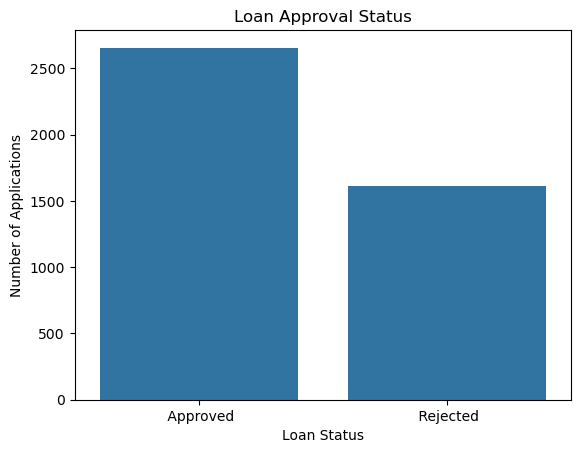

In [33]:
sns.countplot(data=df, x="loan_status")

plt.title("Loan Approval Status")
plt.xlabel("Loan Status")
plt.ylabel("Number of Applications")
plt.show()

In [34]:
#cheack the text values
print(df.select_dtypes(include="object").columns)

for col in df.select_dtypes(include="object").columns:
    print("\n", col)
    print(df[col].unique())

Index(['education', 'self_employed', 'loan_status'], dtype='object')

 education
[' Graduate' ' Not Graduate']

 self_employed
[' No' ' Yes']

 loan_status
[' Approved' ' Rejected']


In [35]:
#create Target Columns
df["loan_status"] = df["loan_status"].str.strip().str.title()

print(df["loan_status"].value_counts())

loan_status
Approved    2656
Rejected    1613
Name: count, dtype: int64


In [36]:
df = pd.get_dummies(
    df,
    columns=["education", "self_employed"],
    drop_first=True,
    dtype=int
)

df["loan_status"] = df["loan_status"].map({
    "Approved": 1,
    "Rejected": 0
})

df.head()

,loan_id,no_of_dependents,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status,education_ Not Graduate,self_employed_ Yes
0,1,2,9600000,29900000,12,778,2400000,17600000,22700000,8000000,1,0,0
1,2,0,4100000,12200000,8,417,2700000,2200000,8800000,3300000,0,1,1
2,3,3,9100000,29700000,20,506,7100000,4500000,33300000,12800000,0,0,0
3,4,3,8200000,30700000,8,467,18200000,3300000,23300000,7900000,0,0,0
4,5,5,9800000,24200000,20,382,12400000,8200000,29400000,5000000,0,1,1


In [37]:
X = df.drop("loan_status", axis=1)
y = df["loan_status"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (4269, 12)
Target shape: (4269,)


In [38]:
X = X.drop(columns=["loan_id"], errors="ignore")

In [39]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (3415, 11)
Testing data: (854, 11)


In [40]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaling completed!")
print("Training shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)

Scaling completed!
Training shape: (3415, 11)
Testing shape: (854, 11)


In [41]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

model.fit(X_train_scaled, y_train)

print("Model Training Completed!")

Model Training Completed!


In [42]:
from sklearn.metrics import accuracy_score

y_pred = model.predict(X_test_scaled)

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

Model Accuracy: 91.33 %


In [43]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [44]:
import pickle

with open("model.pkl", "wb") as f:
    pickle.dump(model, f)

with open("scaler.pkl", "wb") as f:
    pickle.dump(scaler, f)

with open("feature_columns.pkl", "wb") as f:
    pickle.dump(list(X_train.columns), f)

print("All files saved successfully!")

All files saved successfully!


In [45]:
import os

print("Current folder:", os.getcwd())
print(os.listdir())

Current folder: C:\Users\SAVITRI\Downloads
['.ipynb_checkpoints', '10459500_10761432_1783850991387 (1) (1).pdf', '10459500_10761432_1783850991387 (1).pdf', '10459500_10761432_1783850991387.pdf', '341769349341_1673090564_Latest_Happy_Republic_Day_Photo_Frame_Download_Free.png', '841769349493_1768974707_Republic_Day_Photo_Adding_Frame_Template_2026_Free_Edit_Card_Online_Create.png', 'Abhyankar_side_bill.pdf (1).docx', 'Abhyankar_side_bill.pdf.docx', 'an-introduction-to-social-sciences-article-rifat-j-quadiri.pdf', 'Anaconda3-2025.12-2-Windows-x86_64.exe', 'android-studio-2025.1.4.8-windows.exe', 'android-studio-panda2-windows (1).exe', 'android-studio-panda2-windows.exe', 'ARIHANT COMPUTER AWARENESS ENGLISH EDITION _260130_213307.docx', 'ARIHANT COMPUTER AWARENESS ENGLISH EDITION _260130_213307.pdf', 'Atlas Labels Training (2) (1) (1).pdf', 'Atlas Labels Training (2) (1).pdf', 'autopsy-4.22.1-64bit.msi', 'B03-10am python prog (2)', 'B03-10am python prog (2).zip', 'Background Viz.png', 'b

In [46]:
import os

print(os.getcwd())
print(os.listdir())

C:\Users\SAVITRI\Downloads
['.ipynb_checkpoints', '10459500_10761432_1783850991387 (1) (1).pdf', '10459500_10761432_1783850991387 (1).pdf', '10459500_10761432_1783850991387.pdf', '341769349341_1673090564_Latest_Happy_Republic_Day_Photo_Frame_Download_Free.png', '841769349493_1768974707_Republic_Day_Photo_Adding_Frame_Template_2026_Free_Edit_Card_Online_Create.png', 'Abhyankar_side_bill.pdf (1).docx', 'Abhyankar_side_bill.pdf.docx', 'an-introduction-to-social-sciences-article-rifat-j-quadiri.pdf', 'Anaconda3-2025.12-2-Windows-x86_64.exe', 'android-studio-2025.1.4.8-windows.exe', 'android-studio-panda2-windows (1).exe', 'android-studio-panda2-windows.exe', 'ARIHANT COMPUTER AWARENESS ENGLISH EDITION _260130_213307.docx', 'ARIHANT COMPUTER AWARENESS ENGLISH EDITION _260130_213307.pdf', 'Atlas Labels Training (2) (1) (1).pdf', 'Atlas Labels Training (2) (1).pdf', 'autopsy-4.22.1-64bit.msi', 'B03-10am python prog (2)', 'B03-10am python prog (2).zip', 'Background Viz.png', 'blue-futuristic-w